# Nyando Flood Monitor - Sprint 3 Fine-Tuning
 Ensure you have uploaded the `Nyando_Dataset` folder and the `unet_sen1floods_best.pth` base weights to your Google Drive.

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install rasterio

In [ ]:
# 2. Imports and Dataset Setup
import os
import csv
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import rasterio
import numpy as np
import random

class NyandoFloodDataset(Dataset):
    def __init__(self, dataset_dir, split="train", transform=True):
        self.dataset_dir = dataset_dir
        self.transform = transform
        self.patches = []

        csv_path = os.path.join(dataset_dir, f"nyando_split_{split}.csv")
        with open(csv_path, 'r') as f:
            reader = csv.reader(f)
            for row in reader:
                if row:
                    self.patches.append(row[0])

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        patch_id = self.patches[idx]

        sar_path = os.path.join(self.dataset_dir, "S1Hand", f"{patch_id}_S1Hand.tif")
        mask_path = os.path.join(self.dataset_dir, "LabelHand", f"{patch_id}_LabelHand.tif")

        with rasterio.open(sar_path) as src:
            sar = src.read().astype(np.float32)
            sar = np.nan_to_num(sar)
            # Per-channel Z-score normalization — must match 05_inference.py
            for c in range(sar.shape[0]):
                mean, std = np.mean(sar[c]), np.std(sar[c])
                if std > 0:
                    sar[c] = (sar[c] - mean) / std

        with rasterio.open(mask_path) as src:
            mask = src.read(1).astype(np.float32)

        if self.transform:
            if random.random() > 0.5:
                sar = np.flip(sar, axis=1)
                mask = np.flip(mask, axis=0)
            if random.random() > 0.5:
                sar = np.flip(sar, axis=2)
                mask = np.flip(mask, axis=1)
            k = random.randint(0, 3)
            sar = np.rot90(sar, k, axes=(1, 2))
            mask = np.rot90(mask, k, axes=(0, 1))

        sar = np.ascontiguousarray(sar)
        mask = np.ascontiguousarray(mask)

        return torch.from_numpy(sar), torch.from_numpy(mask).unsqueeze(0)

In [ ]:
# 3. Model Architecture
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2, out_channels=1):
        super().__init__()
        self.down1 = DoubleConv(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.down3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(256, 512)
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(128, 64)
        self.out_conv = nn.Conv2d(64, out_channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x1 = self.down1(x)
        x2 = self.down2(self.pool1(x1))
        x3 = self.down3(self.pool2(x2))
        x_btn = self.bottleneck(self.pool3(x3))
        x = self.conv1(torch.cat([self.up1(x_btn), x3], dim=1))
        x = self.conv2(torch.cat([self.up2(x), x2], dim=1))
        x = self.conv3(torch.cat([self.up3(x), x1], dim=1))
        return self.sigmoid(self.out_conv(x))

In [ ]:
# 4. Loss Function and Metrics
class MaskedBCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCELoss(reduction='none')

    def forward(self, pred, target):
        valid_mask = (target != -1).float()
        safe_target = target.clamp(min=0)
        bce_loss = self.bce(pred, safe_target)
        bce_loss = (bce_loss * valid_mask).sum() / (valid_mask.sum() + 1e-8)
        smooth = 1e-5
        pred_flat = pred.view(-1)
        target_flat = safe_target.view(-1)
        mask_flat = valid_mask.view(-1)
        intersection = (pred_flat * target_flat * mask_flat).sum()
        denominator = (pred_flat * mask_flat).sum() + (target_flat * mask_flat).sum()
        dice_loss = 1 - ((2. * intersection + smooth) / (denominator + smooth))
        return bce_loss + dice_loss

def calculate_metrics(pred, target):
    valid_mask = (target != -1)
    preds_bin = (pred > 0.5).bool() & valid_mask
    targets_bin = (target > 0).bool() & valid_mask
    tp = (preds_bin & targets_bin).float().sum()
    fp = (preds_bin & ~targets_bin & valid_mask).float().sum()
    fn = (~preds_bin & targets_bin & valid_mask).float().sum()
    precision = (tp / (tp + fp + 1e-8)).item()
    recall = (tp / (tp + fn + 1e-8)).item()
    f1 = (2 * tp / (2 * tp + fp + fn + 1e-8)).item()
    iou = (tp / (tp + fp + fn + 1e-8)).item()
    return iou, f1, precision, recall

In [ ]:
# 5. Training Loop
def train_model(dataset_dir, base_weights_path="unet_sen1floods_best.pth", epochs=100, batch_size=8, lr=1e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    train_dataset = NyandoFloodDataset(dataset_dir, split="train", transform=True)
    val_dataset = NyandoFloodDataset(dataset_dir, split="val", transform=False)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = UNet(in_channels=2, out_channels=1).to(device)

    if os.path.exists(base_weights_path):
        model.load_state_dict(torch.load(base_weights_path, map_location=device))
        print(f"Successfully loaded base weights from {base_weights_path}")
    else:
        print(f"WARNING: Base weights '{base_weights_path}' not found!")

    criterion = MaskedBCEDiceLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    patience = 10
    best_iou = 0.0
    epochs_no_improve = 0
    # Save to Drive so weights survive runtime restarts
    save_path = "/content/drive/MyDrive/nyando_finetuned_model.pth"

    history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_f1": []}

    print(f"Starting Fine-Tuning for {epochs} epochs...")
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for sar, mask in train_loader:
            sar, mask = sar.to(device), mask.to(device)
            optimizer.zero_grad()
            outputs = model(sar)
            loss = criterion(outputs, mask)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss, val_iou, val_f1 = 0, 0, 0
        with torch.no_grad():
            for sar, mask in val_loader:
                sar, mask = sar.to(device), mask.to(device)
                outputs = model(sar)
                loss = criterion(outputs, mask)
                val_loss += loss.item()
                iou, f1, _, _ = calculate_metrics(outputs, mask)
                val_iou += iou
                val_f1 += f1

        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        avg_val_iou = val_iou / len(val_loader)
        avg_val_f1 = val_f1 / len(val_loader)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_iou"].append(avg_val_iou)
        history["val_f1"].append(avg_val_f1)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f} | Val F1: {avg_val_f1:.4f}")

        if avg_val_iou > best_iou:
            best_iou = avg_val_iou
            epochs_no_improve = 0
            torch.save(model.state_dict(), save_path)
            print(f" -> Best model saved with IoU: {best_iou:.4f}")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs.")
                break

    return history

In [ ]:
# Extract dataset zip from Drive to local disk.
# Local disk is scratch space (wiped on runtime restart) — the zip on Drive
# is the source of truth, so re-running this cell restores everything.
import zipfile, os, shutil
ZIP_PATH = '/content/drive/MyDrive/Nyando_Dataset.zip'
DATASET_DIR = '/content/Nyando_Dataset'
if not (os.path.exists(os.path.join(DATASET_DIR, 'LabelHand'))
        and os.path.exists(os.path.join(DATASET_DIR, 'S1Hand'))
        and os.path.exists(os.path.join(DATASET_DIR, 'nyando_split_train.csv'))):
    os.makedirs(DATASET_DIR, exist_ok=True)
    print('Extracting', ZIP_PATH, '->', DATASET_DIR)
    with zipfile.ZipFile(ZIP_PATH) as z:
        for n in z.namelist():
            rel = n.replace('\\', '/').strip('/')
            if not rel:
                continue
            target = os.path.join(DATASET_DIR, *rel.split('/'))
            if rel.endswith('/') or n.endswith('/'):
                os.makedirs(target, exist_ok=True)
                continue
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with z.open(n) as src, open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)
    print('Done.')
else:
    print('Dataset already at', DATASET_DIR)
print('S1Hand:', len(os.listdir(os.path.join(DATASET_DIR, 'S1Hand'))),
      '| LabelHand:', len(os.listdir(os.path.join(DATASET_DIR, 'LabelHand'))))

Dataset already at /content/Nyando_Dataset
S1Hand: 2450 | LabelHand: 2450


train: 1470 patches -> {'2024-12-08': 9, '2024-09-27': 36, '2023-02-05': 76, '2025-09-22': 40, '2023-10-03': 34, '2024-09-15': 50, '2023-01-24': 67, '2025-05-09': 16, 'hand-labelled': 73, '2025-12-11': 54, '2025-10-28': 28, '2025-12-15': 21, '2024-03-19': 39, '2023-05-12': 9, '2025-08-17': 19, '2023-01-12': 56, '2023-10-27': 23, '2024-08-22': 34, '2023-06-29': 9, '2025-10-12': 35, '2024-07-29': 9, '2023-02-17': 79, '2025-08-25': 13, '2025-09-30': 36, '2025-12-23': 16, '2023-09-21': 21, '2025-11-17': 39, '2024-09-03': 23, '2025-12-27': 21, '2024-01-07': 5, '2024-10-21': 27, '2024-04-12': 17, '2024-05-18': 6, '2025-09-06': 13, '2025-12-03': 63, '2025-07-24': 18, '2023-11-20': 16, '2024-07-17': 7, '2025-11-09': 18, '2024-11-26': 12, '2023-12-26': 11, '2023-04-06': 14, '2025-09-18': 18, '2025-10-04': 25, '2025-07-20': 23, '2025-08-05': 48, '2024-11-02': 19, '2024-12-20': 10, '2023-03-25': 12, '2023-12-02': 10, '2024-03-31': 10, '2025-04-19': 9, '2023-05-24': 9, '2023-04-18': 18, '2023-06-0

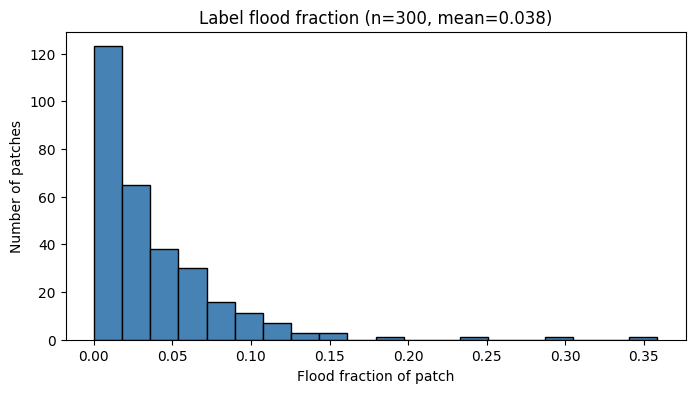

91/2450 patches are degenerate (>95% or 0% flood)
examples: ['Nyando_0_LabelHand.tif', 'Nyando_106_LabelHand.tif', 'Nyando_107_LabelHand.tif', 'Nyando_108_LabelHand.tif', 'Nyando_109_LabelHand.tif', 'Nyando_10_LabelHand.tif', 'Nyando_110_LabelHand.tif', 'Nyando_111_LabelHand.tif', 'Nyando_117_LabelHand.tif', 'Nyando_118_LabelHand.tif']


In [ ]:
# Dataset overview — patches per split/date and label flood fraction
DATASET_DIR = '/content/Nyando_Dataset'
import matplotlib.pyplot as plt
import numpy as np, os, csv, re
from collections import Counter

_DATED = re.compile(r'^Nyando_(\d{4}-\d{2}-\d{2})_\d+$')

for split in ['train', 'val', 'test']:
    ids = [r[0] for r in csv.reader(open(f'{DATASET_DIR}/nyando_split_{split}.csv')) if r]
    by_date = Counter(
        (_DATED.match(i).group(1) if _DATED.match(i) else 'hand-labelled') for i in ids
    )
    print(f'{split}: {len(ids)} patches -> {dict(by_date)}')

# Flood fraction histogram over label patches (sample up to 300)
fracs = []
label_dir = os.path.join(DATASET_DIR, 'LabelHand')
for f in sorted(os.listdir(label_dir)):
    if f.endswith('.tif') and len(fracs) < 300:
        with rasterio.open(os.path.join(label_dir, f)) as src:
            fracs.append(float((src.read(1) == 1).mean()))

plt.figure(figsize=(8, 4))
plt.hist(fracs, bins=20, color='steelblue', edgecolor='black')
plt.xlabel('Flood fraction of patch')
plt.ylabel('Number of patches')
plt.title(f'Label flood fraction (n={len(fracs)}, mean={np.mean(fracs):.3f})')
plt.show()

# Flag suspicious labels: patches that are >95% flood or exactly 0%
all_fracs = []
for f in sorted(os.listdir(label_dir)):
    if f.endswith('.tif'):
        with rasterio.open(os.path.join(label_dir, f)) as src:
            all_fracs.append((f, float((src.read(1) == 1).mean())))
suspicious = [f for f, v in all_fracs if v > 0.95 or v == 0.0]
print(f'{len(suspicious)}/{len(all_fracs)} patches are degenerate (>95% or 0% flood)')
if suspicious[:10]:
    print('examples:', suspicious[:10])

In [ ]:
DRIVE_DIR   = '/content/drive/MyDrive'
DATASET_DIR = '/content/Nyando_Dataset'
BASE_WEIGHTS = DRIVE_DIR + '/unet_sen1floods_best.pth'

history = train_model(DATASET_DIR, base_weights_path=BASE_WEIGHTS)

Using device: cuda
Successfully loaded base weights from /content/drive/MyDrive/unet_sen1floods_best.pth
Starting Fine-Tuning for 100 epochs...
Epoch [1/100] | Train Loss: 0.9348 | Val Loss: 0.8958 | Val IoU: 0.1466 | Val F1: 0.2514
 -> Best model saved with IoU: 0.1466
Epoch [2/100] | Train Loss: 0.8300 | Val Loss: 0.8630 | Val IoU: 0.1739 | Val F1: 0.2917
 -> Best model saved with IoU: 0.1739
Epoch [3/100] | Train Loss: 0.8016 | Val Loss: 0.8449 | Val IoU: 0.1869 | Val F1: 0.3107
 -> Best model saved with IoU: 0.1869
Epoch [4/100] | Train Loss: 0.7849 | Val Loss: 0.8507 | Val IoU: 0.1826 | Val F1: 0.3040
Epoch [5/100] | Train Loss: 0.7754 | Val Loss: 0.8496 | Val IoU: 0.1891 | Val F1: 0.3136
 -> Best model saved with IoU: 0.1891
Epoch [6/100] | Train Loss: 0.7686 | Val Loss: 0.8221 | Val IoU: 0.1991 | Val F1: 0.3269
 -> Best model saved with IoU: 0.1991
Epoch [7/100] | Train Loss: 0.7600 | Val Loss: 0.8473 | Val IoU: 0.1832 | Val F1: 0.3032
Epoch [8/100] | Train Loss: 0.7534 | Val Lo

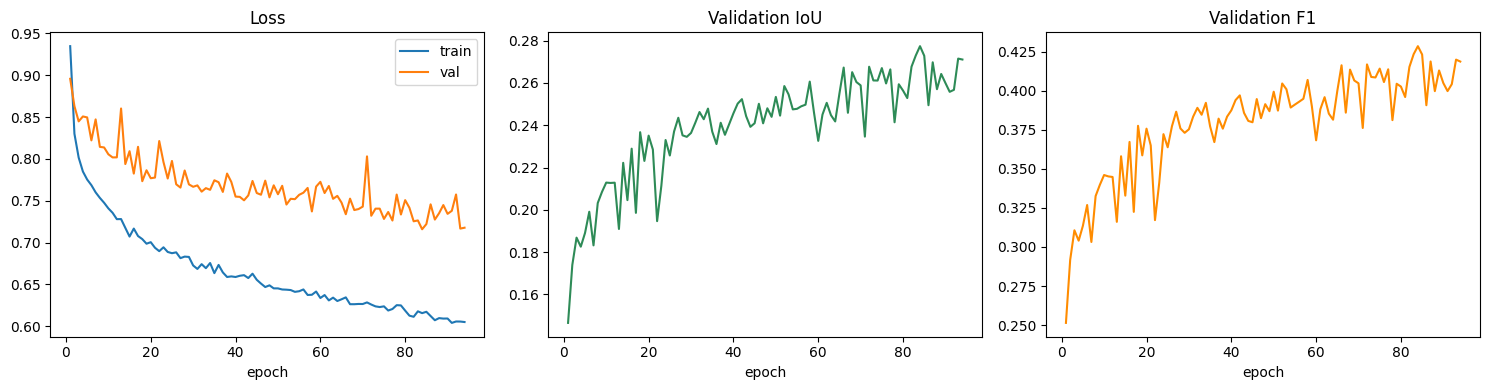

Best val IoU 0.2774 at epoch 84


In [ ]:
# Training curves — loss, IoU, F1 per epoch
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(epochs, history['train_loss'], label='train')
axes[0].plot(epochs, history['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

axes[1].plot(epochs, history['val_iou'], color='seagreen')
axes[1].set_title('Validation IoU'); axes[1].set_xlabel('epoch')

axes[2].plot(epochs, history['val_f1'], color='darkorange')
axes[2].set_title('Validation F1'); axes[2].set_xlabel('epoch')

plt.tight_layout()
plt.show()

best_epoch = int(np.argmax(history['val_iou'])) + 1
print(f"Best val IoU {max(history['val_iou']):.4f} at epoch {best_epoch}")

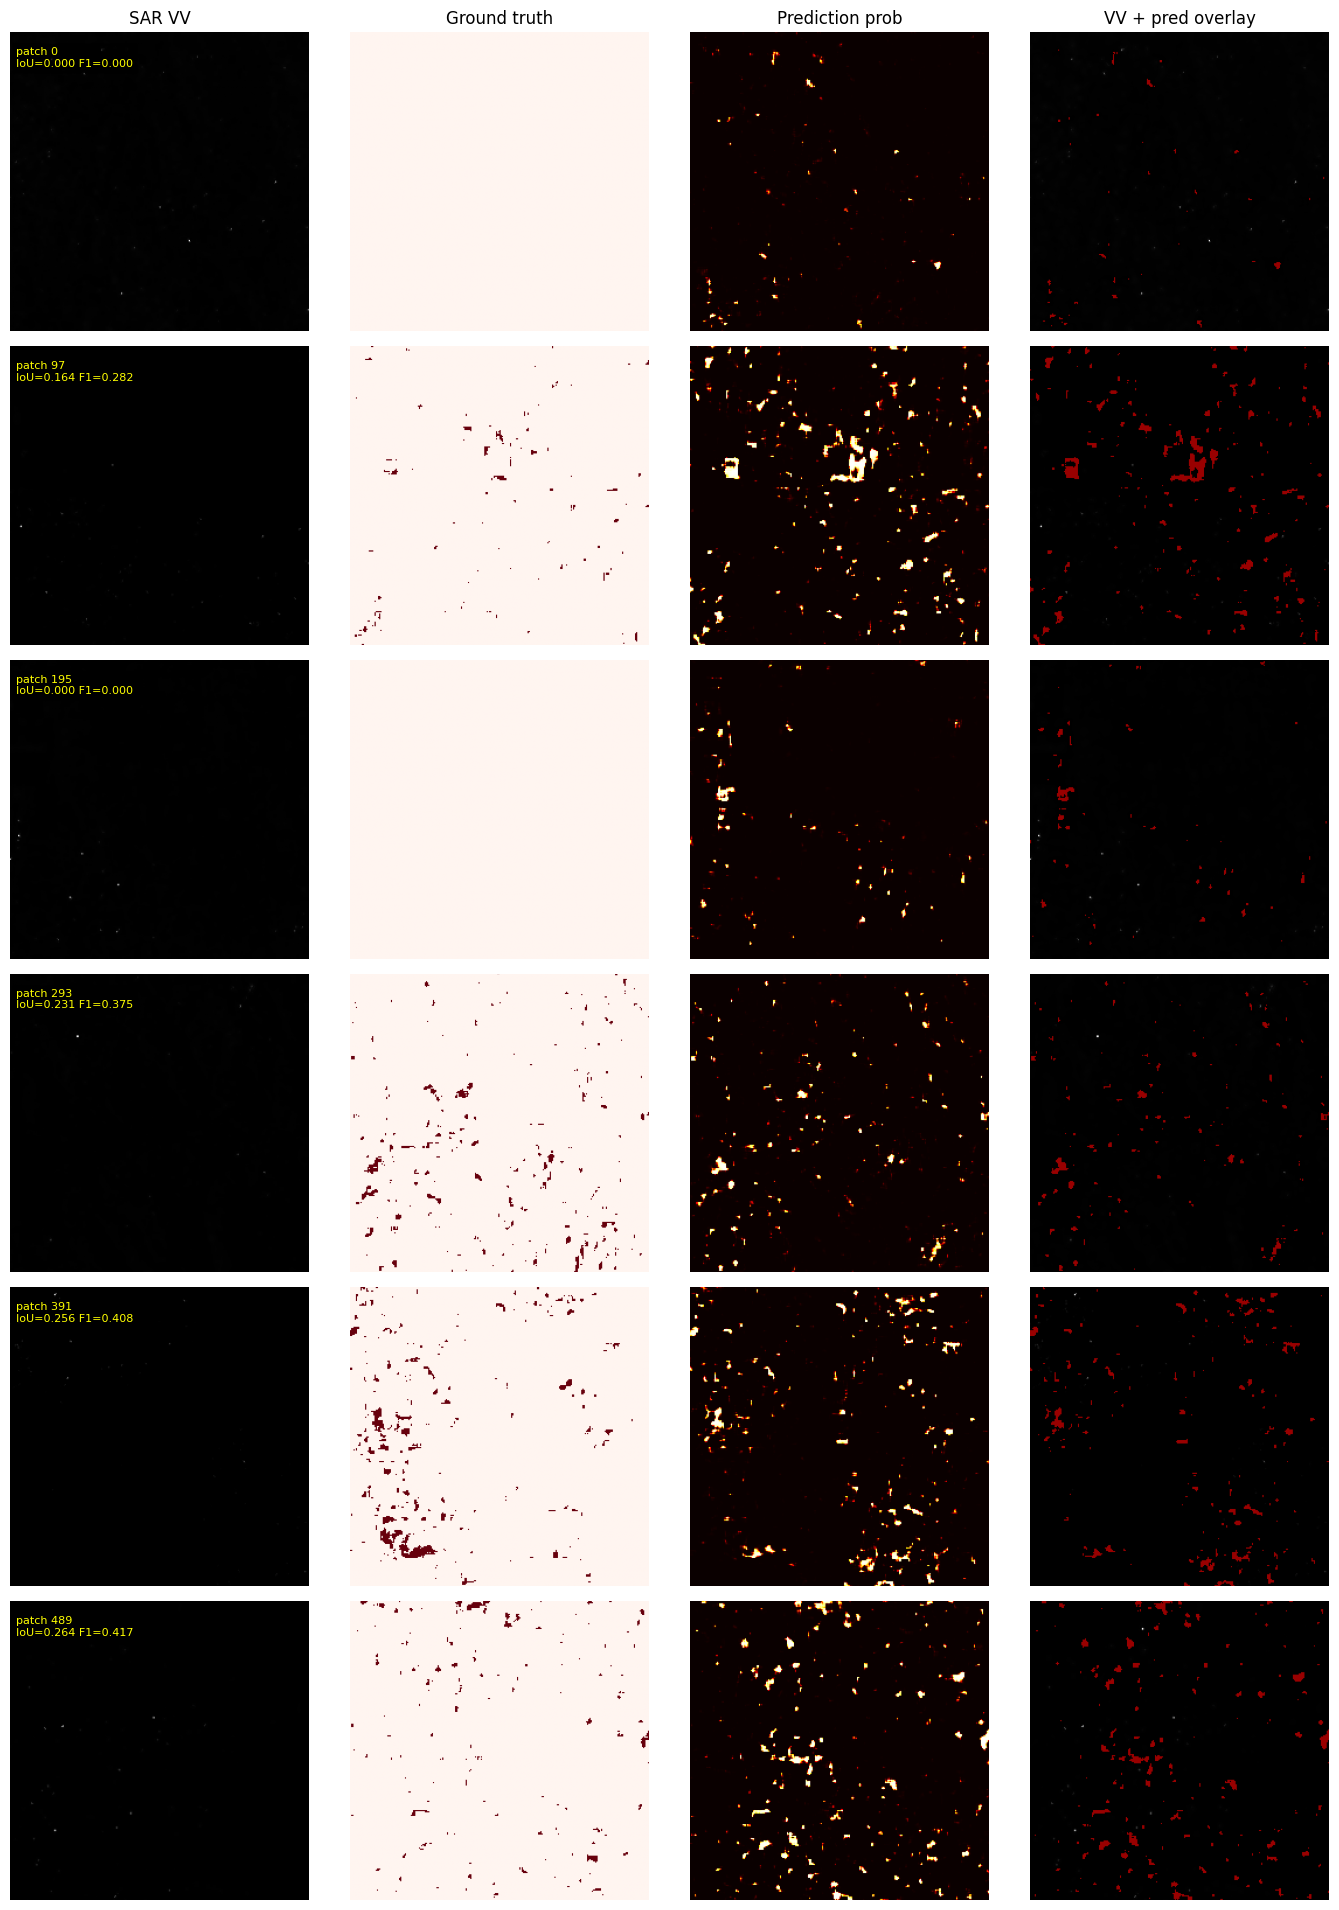

In [ ]:
# Visualise predictions — SAR VV, ground truth, prediction, overlay
import matplotlib.pyplot as plt
import numpy as np, torch, os

DATASET_DIR = '/content/Nyando_Dataset'
MODEL_PATH = '/content/drive/MyDrive/nyando_finetuned_model.pth'
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = os.path.join(DATASET_DIR, 'nyando_finetuned_model.pth')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet(in_channels=2, out_channels=1).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

val_ds = NyandoFloodDataset(DATASET_DIR, split='val', transform=False)
n_show = min(6, len(val_ds))
# spread picks across the val set deterministically
pick = np.linspace(0, len(val_ds) - 1, n_show).astype(int)

fig, axes = plt.subplots(n_show, 4, figsize=(14, 3.2 * n_show))
if n_show == 1:
    axes = axes[None, :]

for row, idx in enumerate(pick):
    sar, mask = val_ds[idx]
    with torch.no_grad():
        pred = model(sar.unsqueeze(0).to(device)).squeeze().cpu().numpy()

    vv_raw = sar[0].numpy()                   # VV channel (z-scored)
    vv = (vv_raw - vv_raw.min()) / (vv_raw.max() - vv_raw.min() + 1e-8)  # -> [0,1]
    gt = mask.squeeze().numpy()               # 0/1
    prob = pred                                # 0..1 probability
    pb = (pred > 0.5).astype(float)

    # VV with prediction overlay (red channel boosted where flood predicted)
    overlay = np.stack([vv, vv, vv], axis=-1)
    overlay[..., 0] = np.clip(vv + pb * 0.6, 0, 1)

    titles = ['SAR VV', 'Ground truth', 'Prediction prob', 'VV + pred overlay']
    for col, (img, title, kw) in enumerate(zip(
            [vv, gt, prob, overlay], titles,
            [dict(cmap='gray'), dict(cmap='Reds', vmin=0, vmax=1),
             dict(cmap='hot', vmin=0, vmax=1), None])):
        ax = axes[row, col]
        if kw is None:
            ax.imshow(img)
        else:
            ax.imshow(img, **kw)
        if row == 0:
            ax.set_title(title)
        ax.axis('off')

    iou, f1, prec, rec = calculate_metrics(
        torch.from_numpy(pred).reshape(1, 1, *pred.shape),
        mask.reshape(1, 1, *mask.shape[1:]))
    axes[row, 0].text(0.02, 0.95, f'patch {idx}\nIoU={iou:.3f} F1={f1:.3f}',
                      transform=axes[row, 0].transAxes, color='yellow',
                      fontsize=8, va='top',
                      bbox=dict(facecolor='black', alpha=0.5, pad=2))

plt.tight_layout()
plt.show()

In [ ]:
import os
print('drive model:', os.path.exists('/content/drive/MyDrive/nyando_finetuned_model.pth'))
print('local model:', os.path.exists('/content/Nyando_Dataset/nyando_finetuned_model.pth'))

drive model: True
local model: False


In [ ]:
# Test Set Evaluation
import torch
from torch.utils.data import DataLoader

DATASET_DIR = '/content/Nyando_Dataset'
save_path   = '/content/drive/MyDrive/nyando_finetuned_model.pth'
if not os.path.exists(save_path):
    save_path = os.path.join(DATASET_DIR, 'nyando_finetuned_model.pth')
device      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet(in_channels=2, out_channels=1).to(device)
model.load_state_dict(torch.load(save_path, map_location=device))
model.eval()

test_dataset = NyandoFloodDataset(DATASET_DIR, split="test", transform=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

test_iou = test_f1 = test_prec = test_rec = 0

with torch.no_grad():
    for sar, mask in test_loader:
        sar, mask = sar.to(device), mask.to(device)
        iou, f1, prec, rec = calculate_metrics(model(sar), mask)
        test_iou += iou; test_f1 += f1; test_prec += prec; test_rec += rec

n = len(test_loader)
print(f"Test IoU:       {test_iou/n:.4f}")
print(f"Test F1:        {test_f1/n:.4f}")
print(f"Test Precision: {test_prec/n:.4f}")
print(f"Test Recall:    {test_rec/n:.4f}")

Test IoU:       0.3502
Test F1:        0.5120
Test Precision: 0.5042
Test Recall:    0.5391


In [ ]:
# Pooled-metrics evaluation: test + val, threshold sweep, hand-labelled subset, zero-shot baseline
import torch, os, re
from torch.utils.data import DataLoader

DATASET_DIR = '/content/Nyando_Dataset'
MODEL_PATH = '/content/drive/MyDrive/nyando_finetuned_model.pth'
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = os.path.join(DATASET_DIR, 'nyando_finetuned_model.pth')
BASE_PATH = '/content/drive/MyDrive/unet_sen1floods_best.pth'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def pooled_metrics(model, dataset, thr=0.5, desc=''):
    """Accumulate TP/FP/FN over the whole split, excluding -1 (ignore) pixels."""
    tp = fp = fn = 0
    with torch.no_grad():
        for sar, mask in DataLoader(dataset, batch_size=8, shuffle=False):
            sar, mask = sar.to(device), mask.to(device)
            valid = (mask != -1)
            p = (model(sar) > thr).bool() & valid
            t = (mask > 0).bool() & valid
            tp += (p & t).sum().item()
            fp += (p & ~t).sum().item()
            fn += (~p & t).sum().item()
    iou = tp / (tp + fp + fn + 1e-8)
    f1  = 2 * tp / (2 * tp + fp + fn + 1e-8)
    prec = tp / (tp + fp + 1e-8)
    rec  = tp / (tp + fn + 1e-8)
    print(f'{desc:44s} IoU={iou:.4f} F1={f1:.4f} P={prec:.4f} R={rec:.4f}  (tp={tp}, fp={fp}, fn={fn})')
    return iou

def load_model(path):
    m = UNet(in_channels=2, out_channels=1).to(device)
    m.load_state_dict(torch.load(path, map_location=device))
    m.eval()
    return m

finetuned = load_model(MODEL_PATH)
base = load_model(BASE_PATH) if os.path.exists(BASE_PATH) else None

test_ds = NyandoFloodDataset(DATASET_DIR, split='test', transform=False)
val_ds  = NyandoFloodDataset(DATASET_DIR, split='val',  transform=False)

print('=== Pooled metrics (TP/FP/FN accumulated, -1 pixels excluded) ===')
pooled_metrics(finetuned, test_ds, desc='finetuned / test')
pooled_metrics(finetuned, val_ds,  desc='finetuned / val')
if base is not None:
    pooled_metrics(base, test_ds, desc='base zero-shot / test')
    pooled_metrics(base, val_ds,  desc='base zero-shot / val')

# --- Label provenance diagnostics -------------------------------------
_DATED = re.compile(r'^Nyando_(\d{4}-\d{2}-\d{2})_\d+$')
import rasterio
def mask_stats(patch_id):
    with rasterio.open(os.path.join(DATASET_DIR, 'LabelHand', f'{patch_id}_LabelHand.tif')) as s:
        m = s.read(1)
    return dict(ignore=float((m == -1).mean()), flood=float((m == 1).mean()),
                other=float(((m != -1) & (m != 1)).mean()))

print('\n=== Label stats: -1 ignore fraction / flood fraction / other ===')
for name, ds in [('test', test_ds), ('val', val_ds)]:
    hand = [p for p in ds.patches if not _DATED.match(p)]
    dated = [p for p in ds.patches if _DATED.match(p)]
    for label, ids in [('hand-labelled', hand), ('dated', dated)]:
        if not ids:
            continue
        st = [mask_stats(p) for p in ids]
        print(f'{name:5s} {label:14s} n={len(ids):4d}  '
              f'ignore={np.mean([s["ignore"] for s in st]):.3f}  '
              f'flood={np.mean([s["flood"] for s in st]):.3f}  '
              f'other={np.mean([s["other"] for s in st]):.3f}')

# Hand-labelled subset eval (with -1 masking now applied)
for name in ['test', 'val']:
    ds_hand = NyandoFloodDataset(DATASET_DIR, split=name, transform=False)
    ds_hand.patches = [p for p in ds_hand.patches if not _DATED.match(p)]
    if len(ds_hand):
        pooled_metrics(finetuned, ds_hand, desc=f'finetuned / {name} hand-labelled only (n={len(ds_hand)})')

# --- Per-date IoU on test (composition check) --------------------------
print('\n=== Per-date pooled IoU on test ===')
by_date = {}
for p in test_ds.patches:
    m = _DATED.match(p)
    by_date.setdefault(m.group(1) if m else 'hand-labelled', []).append(p)
rows = []
for date, ids in sorted(by_date.items()):
    sub = NyandoFloodDataset(DATASET_DIR, split='test', transform=False)
    sub.patches = ids
    iou = pooled_metrics(finetuned, sub, desc=f'test {date} (n={len(ids)})')
    rows.append((date, len(ids), iou))
ious = [r[2] for r in rows]
print(f'per-date IoU: mean={np.mean(ious):.3f} std={np.std(ious):.3f} '
      f'min={min(ious):.3f} max={max(ious):.3f}')

print('\n=== Threshold sweep on val (pooled, -1 excluded) ===')
for thr in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pooled_metrics(finetuned, val_ds, thr=thr, desc=f'val thr={thr}')

=== Pooled metrics (TP/FP/FN accumulated, -1 pixels excluded) ===
finetuned / test                             IoU=0.3628 F1=0.5325 P=0.5241 R=0.5411  (tp=395234, fp=358837, fn=335260)
finetuned / val                              IoU=0.2694 F1=0.4244 P=0.4466 R=0.4043  (tp=336275, fp=416621, fn=495472)
base zero-shot / test                        IoU=0.0253 F1=0.0493 P=0.0279 R=0.2132  (tp=155716, fp=5425488, fn=574778)
base zero-shot / val                         IoU=0.0268 F1=0.0521 P=0.0293 R=0.2399  (tp=199542, fp=6621397, fn=632205)

=== Label stats: -1 ignore fraction / flood fraction / other ===
test  hand-labelled  n=  24  ignore=0.000  flood=0.030  other=0.970
test  dated          n= 466  ignore=0.000  flood=0.022  other=0.978
val   hand-labelled  n=  24  ignore=0.000  flood=0.028  other=0.972
val   dated          n= 466  ignore=0.000  flood=0.026  other=0.974
finetuned / test hand-labelled only (n=24)   IoU=0.0552 F1=0.1046 P=0.2098 R=0.0697  (tp=3241, fp=12206, fn=43277)
fin

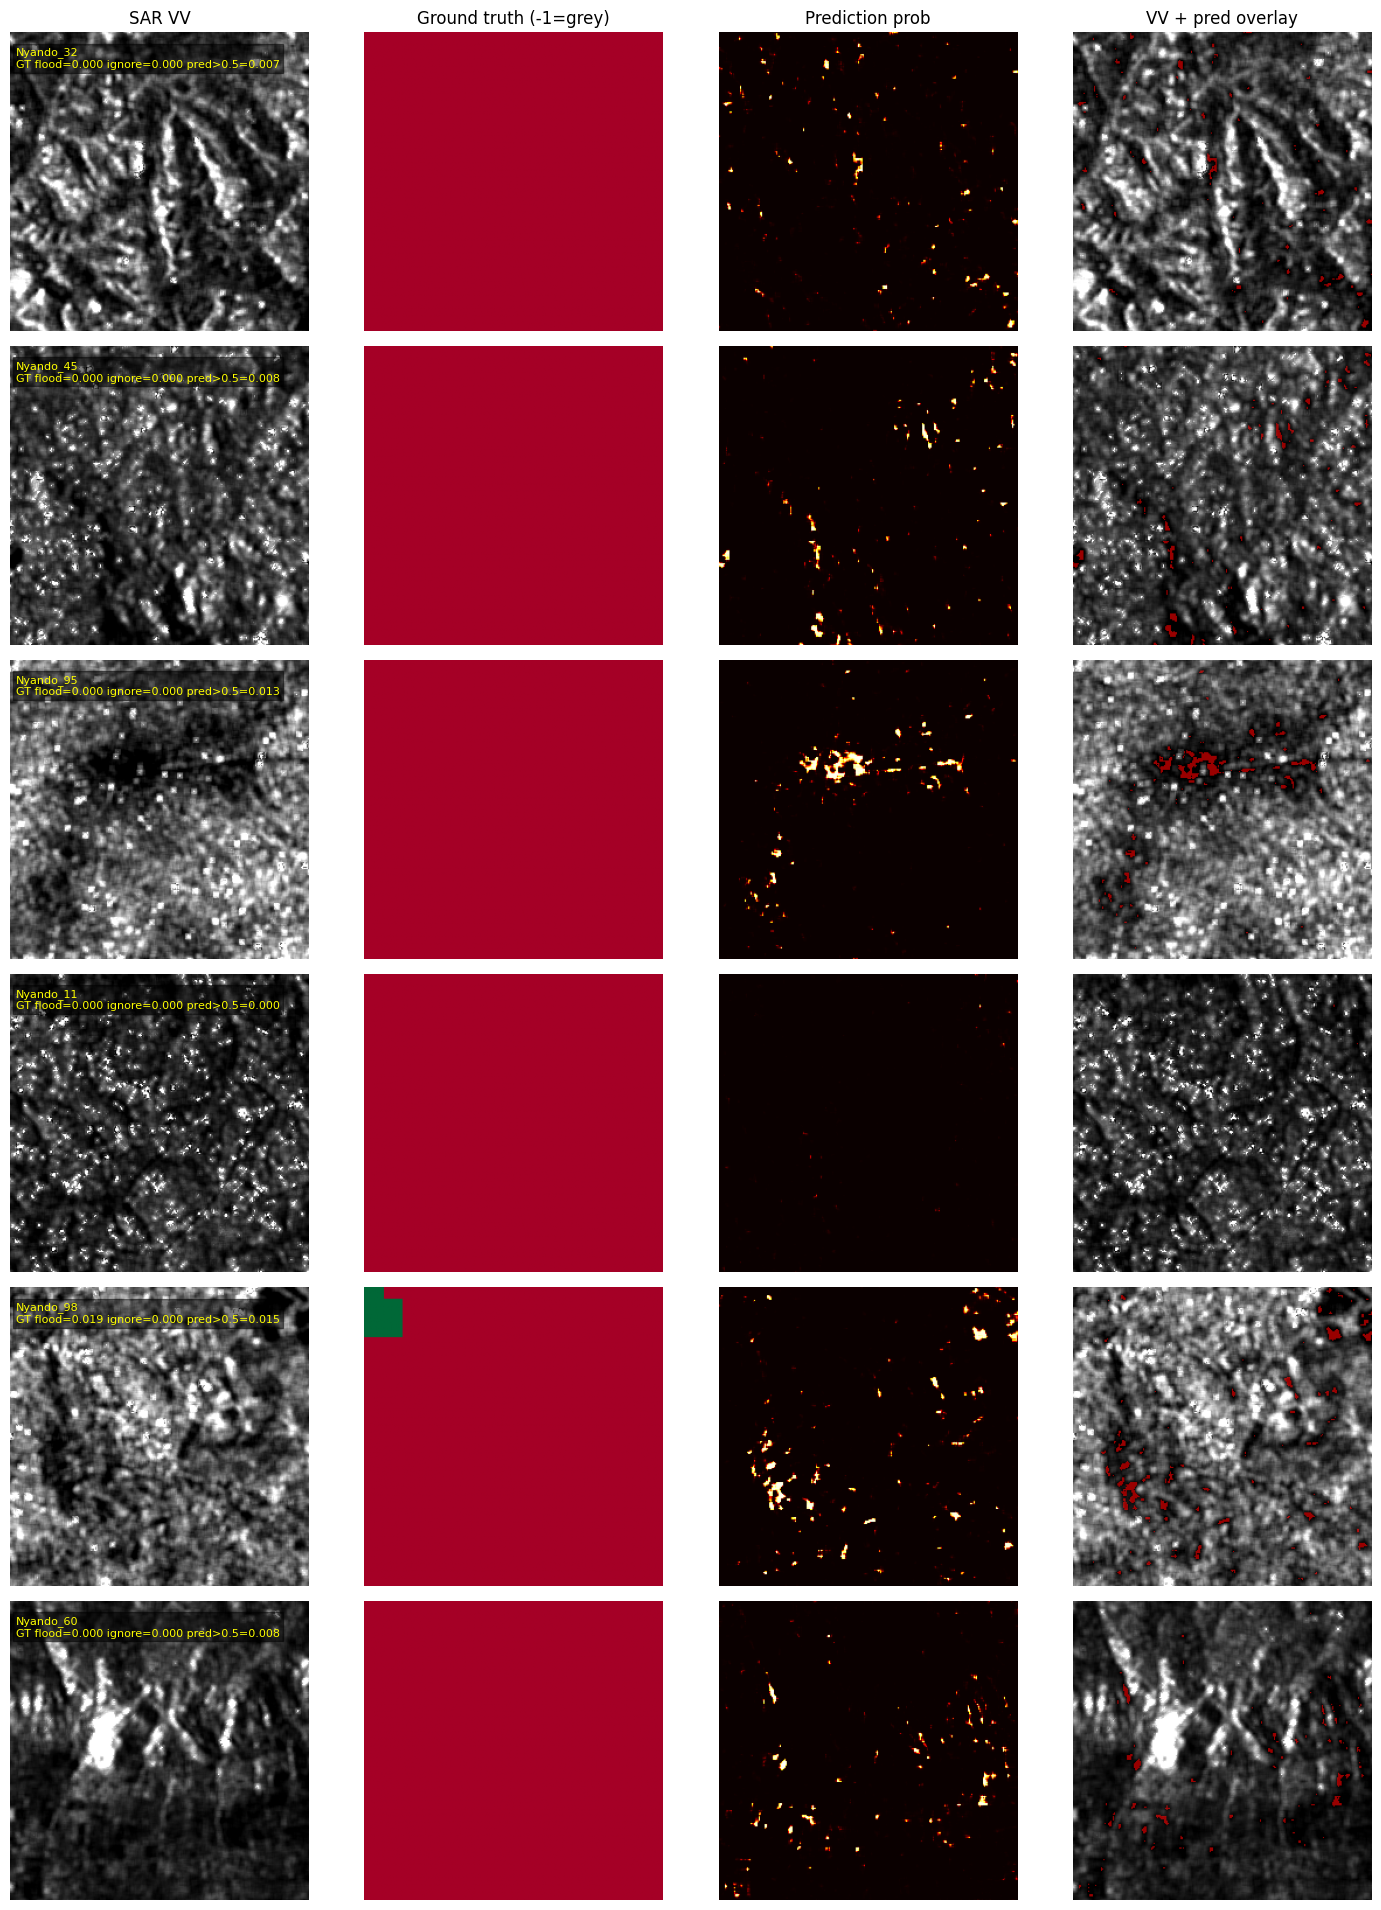

In [ ]:
# Visualise hand-labelled patches — percentile-clipped VV, GT, prediction, overlay
import matplotlib.pyplot as plt
import numpy as np, torch, os, re

DATASET_DIR = '/content/Nyando_Dataset'
MODEL_PATH = '/content/drive/MyDrive/nyando_finetuned_model.pth'
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = os.path.join(DATASET_DIR, 'nyando_finetuned_model.pth')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet(in_channels=2, out_channels=1).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

_DATED = re.compile(r'^Nyando_(\d{4}-\d{2}-\d{2})_\d+$')
hand_ds = NyandoFloodDataset(DATASET_DIR, split='test', transform=False)
hand_ds.patches = [p for p in hand_ds.patches if not _DATED.match(p)]
pick = np.linspace(0, len(hand_ds) - 1, min(6, len(hand_ds))).astype(int)

fig, axes = plt.subplots(len(pick), 4, figsize=(14, 3.2 * len(pick)))
if len(pick) == 1:
    axes = axes[None, :]

for row, idx in enumerate(pick):
    sar, mask = hand_ds[idx]
    with torch.no_grad():
        prob = model(sar.unsqueeze(0).to(device)).squeeze().cpu().numpy()

    vv_raw = sar[0].numpy()
    lo, hi = np.percentile(vv_raw, [2, 98])          # clip extremes for display
    vv = np.clip((vv_raw - lo) / (hi - lo + 1e-8), 0, 1)
    gt = mask.squeeze().numpy()
    gt_show = np.where(gt == -1, 0.5, gt)            # show ignore pixels as grey
    pb = (prob > 0.5).astype(float)

    overlay = np.stack([vv, vv, vv], axis=-1)
    overlay[..., 0] = np.clip(vv + pb * 0.6, 0, 1)

    titles = ['SAR VV', 'Ground truth (-1=grey)', 'Prediction prob', 'VV + pred overlay']
    for col, (img, title, kw) in enumerate(zip(
            [vv, gt_show, prob, overlay], titles,
            [dict(cmap='gray'), dict(cmap='RdYlGn', vmin=0, vmax=1),
             dict(cmap='hot', vmin=0, vmax=1), None])):
        ax = axes[row, col]
        if kw is None:
            ax.imshow(img)
        else:
            ax.imshow(img, **kw)
        if row == 0:
            ax.set_title(title)
        ax.axis('off')

    pid = hand_ds.patches[idx]
    axes[row, 0].text(0.02, 0.95, f'{pid}\nGT flood={float((gt==1).mean()):.3f} '
                      f'ignore={float((gt==-1).mean()):.3f} pred>0.5={pb.mean():.3f}',
                      transform=axes[row, 0].transAxes, color='yellow',
                      fontsize=8, va='top',
                      bbox=dict(facecolor='black', alpha=0.5, pad=2))

plt.tight_layout()
plt.show()